#### PCA wants clean and standardised data

In [1]:
import pandas as pd 
import numpy as np 
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../Files/diabetes.csv')
numerical_cols = ["Pregnancies", "Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age"]


In [10]:
df.head()



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [29]:
## handle missing values
imputer = SimpleImputer(strategy='mean')
data_imputed = imputer.fit_transform(df[numerical_cols])
data_clean = pd.DataFrame(data_imputed,columns=numerical_cols)
data_clean

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72.0,35.0,0.0,33.6,0.627,50.0
1,1.0,85.0,66.0,29.0,0.0,26.6,0.351,31.0
2,8.0,183.0,64.0,0.0,0.0,23.3,0.672,32.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0
...,...,...,...,...,...,...,...,...
763,10.0,101.0,76.0,48.0,180.0,32.9,0.171,63.0
764,2.0,122.0,70.0,27.0,0.0,36.8,0.340,27.0
765,5.0,121.0,72.0,23.0,112.0,26.2,0.245,30.0
766,1.0,126.0,60.0,0.0,0.0,30.1,0.349,47.0


In [12]:
## Standardize important for PCA

scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_clean)


In [13]:
## Apply PCA
pca = PCA(n_components=5)
data_pca = pca.fit_transform(data_scaled)

In [14]:
## Check how much information each component keeps 
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

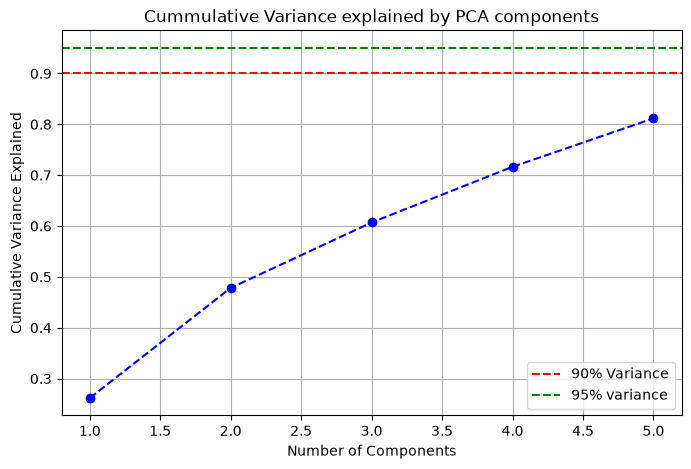

In [16]:
## Plot cummulative variance

plt.figure(figsize=(8,5))
plt.plot(range(1,len(cumulative_variance)+1),cumulative_variance,marker='o', linestyle='--',color='b')
plt.title("Cummulative Variance explained by PCA components")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained")
plt.axhline(y=0.9,color='r',linestyle='--',label='90% Variance')
plt.axhline(y=0.95,color='g',linestyle='--',label='95% variance')
plt.legend()
plt.grid(True)
plt.show()


In [17]:
## print variable info
print("Explanined Variance Ratio : " )
print(explained_variance.round(3))
print("\nCummulative Variance : " )
print(cumulative_variance.round(3))


Explanined Variance Ratio : 
[0.262 0.216 0.129 0.109 0.095]

Cummulative Variance : 
[0.262 0.478 0.607 0.716 0.812]


In [18]:
## Find feature contribution (loadings)
loadings = pd.DataFrame(pca.components_.T, columns=[f'PC{i+1}' for i in range(pca.n_components_)],index=numerical_cols)

print("\nFeature Loadings: ", loadings.round(3))


Feature Loadings:                              PC1    PC2    PC3    PC4    PC5
Pregnancies               0.128  0.594  0.013  0.081  0.476
Glucose                   0.393  0.174 -0.468 -0.404 -0.466
BloodPressure             0.360  0.184  0.535  0.056 -0.328
SkinThickness             0.440 -0.332  0.238  0.038  0.488
Insulin                   0.435 -0.251 -0.337 -0.350  0.347
BMI                       0.452 -0.101  0.362  0.054 -0.253
DiabetesPedigreeFunction  0.271 -0.122 -0.433  0.834 -0.120
Age                       0.198  0.621 -0.075  0.071  0.109


In [19]:
## Use Principal components for logistic regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score



In [20]:
index_of_95 = np.argmax(cumulative_variance >= 0.95)


In [21]:
## np.argmax returns the index of the first 'True'. If no True is found, it returns 0. We must check if the 95% target was actually reached at that index.

In [22]:
if cumulative_variance[index_of_95] >=0.95:
    n_opt = index_of_95+1
else:
    n_opt = len(explained_variance)
print(n_opt)

5


In [23]:
## Use the optimally reduced data for modeling

In [24]:
X_pca_reduced = data_pca[:,:n_opt]
y = df['Outcome']


In [25]:
X_train,X_test,y_train,y_test = train_test_split(X_pca_reduced,y,test_size=0.3, random_state=42,stratify=y)


In [27]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train,y_train)

y_pred = log_reg.predict(X_test)
accuracy = accuracy_score(y_test,y_pred)
print(f"Model Accuracy : {accuracy : .4f}")

Model Accuracy :  0.7403
